<a href="https://colab.research.google.com/github/adika-oloo/-ALXprodev-advanced_git/blob/main/Alx_data_program(_Maize_price_volatility_across_Kenyan_markets)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Problem Statement
#Maize, the base of ugali, is the staple of many Kenyan households, yet its price swings widely between markets and seasons. Which markets and months see the sharpest spikes, and can we forecast them early enough for county food security teams to act?

In [3]:
#Whaht I want to solve
# 1.Where: which markets are most volatile and which are most stable.
# 2.When: is there a repeatable seasonal pattern, such as a lean-season peak before harvest?
# 3.How big: how often prices jump by more than your chosen threshold (for example 15% month on month).
# 4.Can we see it coming: does a seasonal model beat a naive forecast?
# 5 .Action: which markets and months to prioritise for intervention.

In [4]:
#Tech stack
#Task	Tool
#Coding environment	Google Colab or Jupyter
#Cleaning and analysis	Python: pandas, numpy
#Charts	matplotlib, seaborn
#Seasonality and forecasting	statsmodels (STL decomposition, Holt-Winters or SARIMA)
#Maps (optional)	geopandas, or plain latitude/longitude scatter
#Dashboard (optional)	Power BI or Tableau
#Documentation	A README or notes file for your source log

In [5]:
# importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)



In [6]:
#Uploding the data sets
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving wfp_food_prices_ken.csv to wfp_food_prices_ken.csv
Saving wfp_markets_ken.csv to wfp_markets_ken.csv
['wfp_food_prices_ken.csv', 'wfp_markets_ken.csv']


In [9]:
Prices = pd. read_csv ("wfp_food_prices_ken.csv")
Markets = pd. read_csv ("wfp_markets_ken.csv")

In [12]:

for name, d in [("Prices", Prices), ("Markets", Markets)]:
    print(f"\n=== {name} ===")
    print(d.shape)
    print(d.columns.tolist())
    display(d.head(5))


=== Prices ===
(28463, 16)
['date', 'admin1', 'admin2', 'market', 'market_id', 'latitude', 'longitude', 'category', 'commodity', 'commodity_id', 'unit', 'priceflag', 'pricetype', 'currency', 'price', 'usdprice']


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22
1,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,1480.00,20.58
2,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,33.63,0.47
3,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,3246.00,45.15
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.00,0.24



=== Markets ===
(280, 7)
['market_id', 'market', 'countryiso3', 'admin1', 'admin2', 'latitude', 'longitude']


,market_id,market,countryiso3,admin1,admin2,latitude,longitude
0,184,Nairobi,KEN,Nairobi,Nairobi,-1.28,36.82
1,185,Eldoret town (Uasin Gishu),KEN,Rift Valley,Uasin Gishu,0.52,35.28
2,186,Kisumu,KEN,Nyanza,Kisumu,-0.10,34.75
3,187,Kitui,KEN,Eastern,Kitui,-1.37,38.02
4,188,Lodwar (Turkana),KEN,Rift Valley,Turkana,3.12,35.60


In [13]:
Prices["date"] = pd.to_datetime(Prices["date"])
Prices["price"] = pd.to_numeric(Prices["price"], errors="coerce")

merged = Prices.merge(
    Markets[["market_id", "countryiso3"]],
    on="market_id", how="left", indicator=True
)
print(merged["_merge"].value_counts())   # every row should say 'both'

_merge
both          28463
left_only         0
right_only        0
Name: count, dtype: int64


In [14]:
maize = merged[merged["commodity"].str.contains("maize", case=False, na=False)].copy()

series = (maize.groupby(["commodity", "unit", "pricetype"])
          .agg(rows=("price", "size"),
               markets=("market_id", "nunique"),
               first=("date", "min"),
               last=("date", "max"))
          .sort_values("rows", ascending=False))
display(series)

rows  markets      first       last
commodity           unit  pricetype                                     
Maize (white)       KG    Retail     1052        9 2006-01-15 2020-12-15
Maize               KG    Wholesale   860        5 2006-01-15 2022-04-15
Maize flour (white) KG    Retail      758      183 2023-12-15 2026-03-15
Maize flour         KG    Retail      757       32 2018-12-15 2026-09-15
Maize (white)       90 KG Wholesale   733        5 2006-01-15 2020-03-15
Maize               KG    Retail      688       31 2020-08-15 2026-09-15
Maize (white, dry)  KG    Retail      563      162 2023-12-15 2026-03-15
                    90 KG Wholesale   423       20 2021-01-15 2026-08-15

In [15]:
def kg_factor(unit):
    u = str(unit).upper().replace(" ", "")
    if u == "KG": return 1
    if u.endswith("KG") and u[:-2].isdigit(): return int(u[:-2])
    return np.nan   # unknown unit, check these

maize["kg"] = maize["unit"].map(kg_factor)
maize["price_kg"] = maize["price"] / maize["kg"]

print(maize["kg"].isna().sum(), "rows with an unknown unit")
display(maize.groupby(["commodity", "pricetype"])["price_kg"].describe())

0 rows with an unknown unit


count       mean        std        min  \
commodity           pricetype                                            
Maize               Retail      688.0  57.930233  13.432673  25.000000   
                    Wholesale   860.0  28.221105   8.799656  10.430000   
Maize (white)       Retail     1052.0  48.533298  17.268005   6.000000   
                    Wholesale   733.0  28.624377   9.393820  10.491222   
Maize (white, dry)  Retail      563.0  83.588810  21.962766  33.000000   
                    Wholesale   423.0  48.495807  16.020676   8.911111   
Maize flour         Retail      757.0  81.594756  19.535799  50.000000   
Maize flour (white) Retail      758.0  95.794631  18.658415  46.000000   

                                     25%        50%         75%         max  
commodity           pricetype                                                
Maize               Retail     49.000000  55.000000   66.670000  120.000000  
                    Wholesale  22.682500  29.145000   33.955000   60.020000  
Maize (white)       Retail     37.000000  46.850000   60.850000  100.000000  
                    Wholesale  22.222222  29.111111   34.477778   57.777778  
Maize (white, dry)  Retail     67.000000  80.000000  100.000000  152.000000  
                    Wholesale  33.988889  46.700000   61.988889   90.422222  
Maize flour         Retail     65.000000  80.000000  100.000000  150.470000  
Maize flour (white) Retail     83.000000  97.000000  106.000000  195.000000

In [16]:
# Missing values
print(merged.isna().sum())
print((merged["price"] <= 0).sum(), "rows with zero or negative price")

# Exact duplicates
print(merged.duplicated().sum(), "fully duplicated rows")

# Same market, month, commodity, unit and price type appearing more than once
key = ["market_id", "date", "commodity", "unit", "pricetype"]
dups = merged[merged.duplicated(key, keep=False)]
print(len(dups), "rows share the same key")
display(dups.sort_values(key).head(10))

date             0
admin1          68
admin2          68
market           0
market_id        0
latitude        68
longitude       68
category         0
commodity        0
commodity_id     0
unit             0
priceflag        0
pricetype        0
currency         0
price            0
usdprice         0
countryiso3      0
_merge           0
dtype: int64
0 rows with zero or negative price
0 fully duplicated rows
0 rows share the same key


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,countryiso3,_merge


In [17]:
gaps = merged[merged["admin1"].isna()]
print(gaps["market"].value_counts())
print(gaps["commodity"].value_counts().head())
print(gaps["date"].min(), gaps["date"].max())

market
Hola (Tana River)    68
Name: count, dtype: int64
commodity
Maize (white)    68
Name: count, dtype: int64
2015-01-15 00:00:00 2020-12-15 00:00:00


In [18]:
maize = merged[merged["commodity"].str.contains("maize", case=False, na=False)].copy()

series = (maize.groupby(["commodity", "unit", "pricetype"])
          .agg(rows=("price", "size"),
               markets=("market_id", "nunique"),
               first=("date", "min"),
               last=("date", "max"))
          .sort_values("rows", ascending=False))
display(series)

rows  markets      first       last
commodity           unit  pricetype                                     
Maize (white)       KG    Retail     1052        9 2006-01-15 2020-12-15
Maize               KG    Wholesale   860        5 2006-01-15 2022-04-15
Maize flour (white) KG    Retail      758      183 2023-12-15 2026-03-15
Maize flour         KG    Retail      757       32 2018-12-15 2026-09-15
Maize (white)       90 KG Wholesale   733        5 2006-01-15 2020-03-15
Maize               KG    Retail      688       31 2020-08-15 2026-09-15
Maize (white, dry)  KG    Retail      563      162 2023-12-15 2026-03-15
                    90 KG Wholesale   423       20 2021-01-15 2026-08-15

In [19]:
print(maize["priceflag"].value_counts())
print(maize["pricetype"].value_counts())

priceflag
actual       4391
aggregate    1443
Name: count, dtype: int64
pricetype
Retail       3818
Wholesale    2016
Name: count, dtype: int64


In [20]:
print(pd.crosstab(maize["pricetype"], maize["priceflag"]))
print(pd.crosstab(maize["commodity"], [maize["pricetype"], maize["unit"]]))

# Do aggregate rows cluster in time?
print(maize.groupby([maize["date"].dt.year, "priceflag"]).size().unstack(fill_value=0))

priceflag  actual  aggregate
pricetype                   
Retail       2375       1443
Wholesale    2016          0
pricetype           Retail Wholesale     
unit                    KG     90 KG   KG
commodity                                
Maize                  688         0  860
Maize (white)         1052       733    0
Maize (white, dry)     563       423    0
Maize flour            757         0    0
Maize flour (white)    758         0    0
priceflag  actual  aggregate
date                        
2006          144          0
2007          144          0
2008          148          0
2009          154          0
2010          156          0
2011          153          0
2012          145          0
2013          147          0
2014          153          0
2015          217          0
2016          216          0
2017          228          0
2018          227          1
2019          216          1
2020          147          0
2021          169        539
2022          140         

In [21]:
series = (maize.groupby(["commodity", "unit", "pricetype"])
          .agg(rows=("price", "size"),
               markets=("market_id", "nunique"),
               first=("date", "min"),
               last=("date", "max"))
          .sort_values("rows", ascending=False))
display(series)

rows  markets      first       last
commodity           unit  pricetype                                     
Maize (white)       KG    Retail     1052        9 2006-01-15 2020-12-15
Maize               KG    Wholesale   860        5 2006-01-15 2022-04-15
Maize flour (white) KG    Retail      758      183 2023-12-15 2026-03-15
Maize flour         KG    Retail      757       32 2018-12-15 2026-09-15
Maize (white)       90 KG Wholesale   733        5 2006-01-15 2020-03-15
Maize               KG    Retail      688       31 2020-08-15 2026-09-15
Maize (white, dry)  KG    Retail      563      162 2023-12-15 2026-03-15
                    90 KG Wholesale   423       20 2021-01-15 2026-08-15

In [22]:
gaps = merged[merged["admin1"].isna()]
print(gaps["market"].value_counts())
print(gaps["commodity"].value_counts().head())
print(gaps["date"].min(), gaps["date"].max())

market
Hola (Tana River)    68
Name: count, dtype: int64
commodity
Maize (white)    68
Name: count, dtype: int64
2015-01-15 00:00:00 2020-12-15 00:00:00


In [23]:
loc = Markets.set_index("market_id")[["admin1", "admin2", "latitude", "longitude"]]
for c in loc.columns:
    merged[c] = merged[c].fillna(merged["market_id"].map(loc[c]))
print(merged[["admin1", "latitude"]].isna().sum())

admin1      68
latitude    68
dtype: int64


In [24]:
retail = maize[maize["pricetype"] == "Retail"].copy()

# Which commodities carry the aggregate flag?
print(pd.crosstab(retail["commodity"], retail["priceflag"]))

# Coverage per market for the main candidate series
def coverage(d):
    g = d.groupby("market")["date"].agg(first="min", last="max", n="nunique")
    g["span"] = ((g["last"].dt.year - g["first"].dt.year) * 12
                 + g["last"].dt.month - g["first"].dt.month + 1)
    g["coverage"] = (g["n"] / g["span"]).round(2)
    return g.sort_values("n", ascending=False)

main = retail[retail["commodity"] == "Maize"]
display(coverage(main))

flour = retail[retail["commodity"] == "Maize flour"]
display(coverage(flour).head(15))

priceflag            actual  aggregate
commodity                             
Maize                     1        687
Maize (white)          1052          0
Maize (white, dry)      563          0
Maize flour               1        756
Maize flour (white)     758          0


,first,last,n,span,coverage
market,,,,,
IFO (Daadab),2021-03-15,2026-09-15,54,67,0.81
Kakuma 3,2021-02-15,2026-08-15,53,67,0.79
Kalobeyei (Village 1),2021-01-15,2026-08-15,52,68,0.76
Kakuma 4,2021-02-15,2026-08-15,50,67,0.75
Hagadera (Daadab),2021-01-15,2026-08-15,48,68,0.71
Kalobeyei (Village 2),2021-01-15,2026-08-15,48,68,0.71
Kakuma 2,2021-02-15,2026-08-15,47,67,0.70
Ethiopia (Kakuma),2021-02-15,2026-09-15,45,68,0.66
HongKong (Kakuma),2021-02-15,2026-09-15,43,68,0.63


,first,last,n,span,coverage
market,,,,,
Dagahaley (Daadab),2018-12-15,2026-08-15,56,93,0.60
IFO (Daadab),2021-03-15,2026-09-15,55,67,0.82
Kakuma 3,2021-02-15,2026-08-15,53,67,0.79
Hagadera (Daadab),2021-01-15,2026-08-15,53,68,0.78
Kalobeyei (Village 1),2021-01-15,2026-08-15,52,68,0.76
Kakuma 4,2021-02-15,2026-08-15,51,67,0.76
Kakuma 2,2021-02-15,2026-08-15,49,67,0.73
Kalobeyei (Village 2),2021-01-15,2026-08-15,48,68,0.71
HongKong (Kakuma),2021-02-15,2026-09-15,46,68,0.68


In [25]:
A = retail[retail["commodity"] == "Maize (white)"].copy()
cov = coverage(A)
display(cov)

# Spread of coverage by year, per market
display(pd.crosstab(A["market"], A["date"].dt.year))

# Check which of the 9 markets have location info
print(A[["market", "admin1", "latitude"]].drop_duplicates())

,first,last,n,span,coverage
market,,,,,
Kitui,2006-01-15,2020-12-15,180,180,1.00
Mandera,2006-01-15,2020-12-15,179,180,0.99
Lodwar (Turkana),2006-01-15,2020-12-15,177,180,0.98
Marsabit,2006-01-15,2020-12-15,171,180,0.95
Kilifi,2015-01-15,2020-12-15,71,72,0.99
Kajiado,2015-01-15,2020-12-15,70,72,0.97
Garissa,2015-01-15,2020-12-15,68,72,0.94
Hola (Tana River),2015-01-15,2020-12-15,68,72,0.94
Marigat (Baringo),2015-01-15,2020-12-15,68,72,0.94


date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
market,,,,,,,,,,,,,,,
Garissa,0,0,0,0,0,0,0,0,0,12,11,12,12,12,9
Hola (Tana River),0,0,0,0,0,0,0,0,0,12,11,12,12,12,9
Kajiado,0,0,0,0,0,0,0,0,0,12,11,12,12,12,11
Kilifi,0,0,0,0,0,0,0,0,0,12,11,12,12,12,12
Kitui,12,12,12,12,12,12,12,12,12,12,12,12,12,12,12
Lodwar (Turkana),12,12,12,12,12,12,12,12,11,12,11,12,12,12,11
Mandera,12,12,12,12,12,12,12,12,12,12,11,12,12,12,12
Marigat (Baringo),0,0,0,0,0,0,0,0,0,12,11,12,12,9,12
Marsabit,12,12,12,12,12,9,12,11,12,11,11,12,12,12,9


                 market         admin1  latitude
4                 Kitui        Eastern     -1.37
8              Marsabit        Eastern      2.33
18              Mandera  North Eastern      3.94
25     Lodwar (Turkana)    Rift Valley      3.12
3521  Hola (Tana River)            NaN       NaN
3522             Kilifi          Coast     -3.63
3542            Garissa  North Eastern     -0.46
3550  Marigat (Baringo)    Rift Valley      0.46
3552            Kajiado    Rift Valley     -1.84


In [26]:
A = A.sort_values(["market", "date"])
A["ym"] = A["date"].dt.to_period("M")

# Wide table: one column per market, one row per month, price in KES per KG
wide = A.pivot_table(index="ym", columns="market", values="price")
wide = wide.reindex(pd.period_range(wide.index.min(), wide.index.max(), freq="M"))

# 1. Which months are missing inside each market's own span?
for m in wide.columns:
    s = wide[m]
    inside = s.loc[s.first_valid_index():s.last_valid_index()]
    print(m, list(inside[inside.isna()].index.astype(str)))

# 2. Range check
display(wide.describe().T[["min", "max", "mean"]])

# 3. Month-on-month changes, to find suspicious jumps
pct = wide.pct_change(fill_method=None)
print(pct.stack().describe())
big = pct.stack().loc[lambda s: s.abs() > 0.30].sort_values()
display(big)

Garissa ['2016-04', '2020-01', '2020-02', '2020-03']
Hola (Tana River) ['2016-04', '2020-01', '2020-02', '2020-03']
Kajiado ['2016-04', '2020-08']
Kilifi ['2016-04']
Kitui []
Lodwar (Turkana) ['2014-03', '2016-04', '2020-03']
Mandera ['2016-04']
Marigat (Baringo) ['2016-04', '2019-01', '2019-02', '2019-03']
Marsabit ['2011-10', '2011-11', '2011-12', '2013-03', '2015-11', '2016-04', '2020-01', '2020-02', '2020-04']


,min,max,mean
market,,,
Garissa,50.0,80.00,60.941176
Hola (Tana River),31.0,80.00,50.812647
Kajiado,40.0,75.00,51.125857
Kilifi,33.9,87.90,43.701408
Kitui,6.0,58.00,30.768111
Lodwar (Turkana),26.0,100.00,61.007345
Mandera,20.0,85.00,57.096704
Marigat (Baringo),33.0,81.00,46.283824
Marsabit,12.0,62.22,41.356667


count    1024.000000
mean        0.009179
std         0.109137
min        -0.538462
25%        -0.035373
50%         0.000000
75%         0.041667
max         1.500000
dtype: float64


,,0
,market,
2010-06,Kitui,-0.538462
2007-03,Kitui,-0.529412
2017-06,Kilifi,-0.341297
2010-02,Kitui,-0.333333
2008-11,Marsabit,0.312500
2018-10,Hola (Tana River),0.316667
2017-06,Hola (Tana River),0.333333
2006-11,Mandera,0.347826
2016-10,Mandera,0.351931


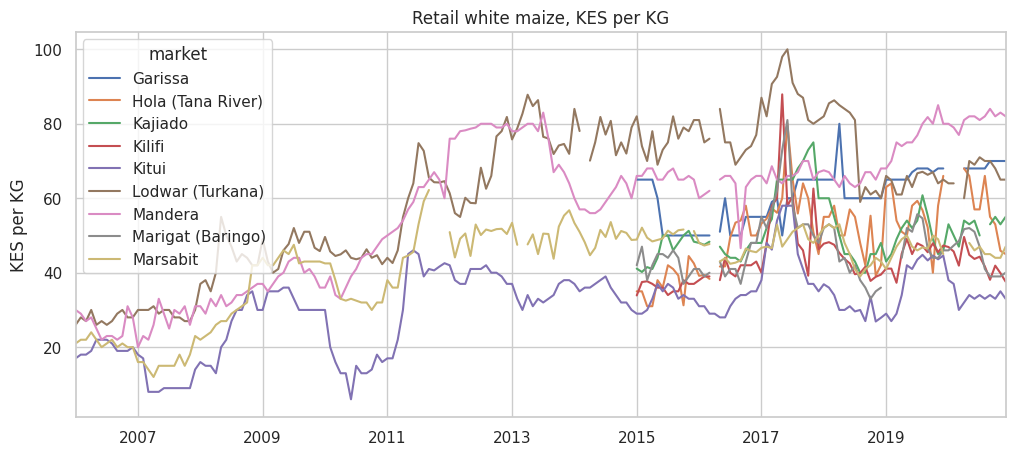

In [27]:
wide.plot(figsize=(12, 5), title="Retail white maize, KES per KG")
plt.ylabel("KES per KG"); plt.show()

In [28]:
# Kitui's suspicious stretches against the other long-run markets
cmp_cols = ["Kitui", "Mandera", "Lodwar (Turkana)", "Marsabit"]
display(wide.loc["2010-03":"2010-09", cmp_cols])
display(wide.loc["2007-01":"2007-05", cmp_cols])

# Share of months where the price is exactly unchanged, per market
same = (wide.diff() == 0).sum() / wide.notna().sum()
display(same.round(2).sort_values(ascending=False))

market,Kitui,Mandera,Lodwar (Turkana),Marsabit
2010-03,16.0,34.0,44.50,38.0
2010-04,13.0,33.0,44.93,33.0
2010-05,13.0,36.0,46.00,32.5
2010-06,6.0,39.0,44.00,33.0
2010-07,15.0,41.0,43.61,32.5
2010-08,13.0,44.0,44.00,32.0
2010-09,13.0,45.0,46.29,32.0


market,Kitui,Mandera,Lodwar (Turkana),Marsabit
2007-01,18.0,20.0,30.0,16.0
2007-02,17.0,23.0,30.0,16.0
2007-03,8.0,22.0,30.0,14.0
2007-04,8.0,26.0,31.0,12.0
2007-05,8.0,33.0,29.0,15.0


,0
market,
Garissa,0.69
Kitui,0.25
Kajiado,0.17
Mandera,0.16
Marigat (Baringo),0.13
Marsabit,0.11
Kilifi,0.10
Hola (Tana River),0.09
Lodwar (Turkana),0.08


In [29]:
filled = wide.interpolate(limit=3, limit_area="inside")
was_filled = wide.isna() & filled.notna()
print(was_filled.sum().sum(), "months interpolated")
print(filled.isna().sum())          # anything still missing outside a market's own span

# Save (keep raw and filled separately)
wide.to_csv("maize_white_retail_monthly_raw.csv")
filled.to_csv("maize_white_retail_monthly_filled.csv")
was_filled.to_csv("maize_white_retail_interpolation_flags.csv")

28 months interpolated
market
Garissa              108
Hola (Tana River)    108
Kajiado              108
Kilifi               108
Kitui                  0
Lodwar (Turkana)       0
Mandera                0
Marigat (Baringo)    108
Marsabit               0
dtype: int64


In [30]:
final = filled.copy()
final.loc[pd.Period("2010-06"), "Kitui"] = np.nan          # flagged outlier
final = final.interpolate(limit=3, limit_area="inside")    # refill that one point

# Keep a version with the original value, for the sensitivity check
final_keep = filled.copy()

final.to_csv("maize_white_retail_monthly_final.csv")

In [31]:
win = final.loc["2015-01":"2020-12"]
logret = np.log(win).diff()

vol = pd.DataFrame({
    "sd_log_change": logret.std(),
    "cv": win.std() / win.mean(),
    "unchanged_share": (win.diff() == 0).sum() / win.notna().sum(),
    "mean_price": win.mean(),
}).round(3)

vol["rank_sd"] = vol["sd_log_change"].rank(ascending=False)
vol["rank_cv"] = vol["cv"].rank(ascending=False)
display(vol.sort_values("sd_log_change", ascending=False))

,sd_log_change,cv,unchanged_share,mean_price,rank_sd,rank_cv
market,,,,,,
Hola (Tana River),0.143,0.205,0.083,51.337,1.0,1.0
Kilifi,0.121,0.186,0.097,43.629,2.0,3.0
Marigat (Baringo),0.090,0.178,0.125,45.956,3.0,4.0
Kitui,0.089,0.204,0.153,35.798,4.0,2.0
Kajiado,0.069,0.154,0.167,51.083,5.0,5.0
Garissa,0.068,0.119,0.708,61.090,6.0,7.0
Lodwar (Turkana),0.067,0.132,0.083,74.347,7.0,6.0
Mandera,0.061,0.108,0.181,69.762,8.0,8.0
Marsabit,0.046,0.072,0.028,47.145,9.0,9.0


market,Kitui,Mandera,Lodwar (Turkana),Marsabit,average
1,1.000,0.983,1.027,1.012,1.005
2,0.958,0.979,0.980,0.991,0.977
3,0.886,0.986,0.965,0.974,0.953
4,0.920,0.995,1.008,0.993,0.979
5,1.018,1.017,1.043,0.986,1.016
6,1.032,1.000,1.038,0.980,1.013
7,1.054,1.007,1.040,0.996,1.024
8,1.014,1.022,0.994,0.999,1.007
9,0.985,0.990,0.988,0.998,0.990
10,1.005,1.015,0.988,1.000,1.002


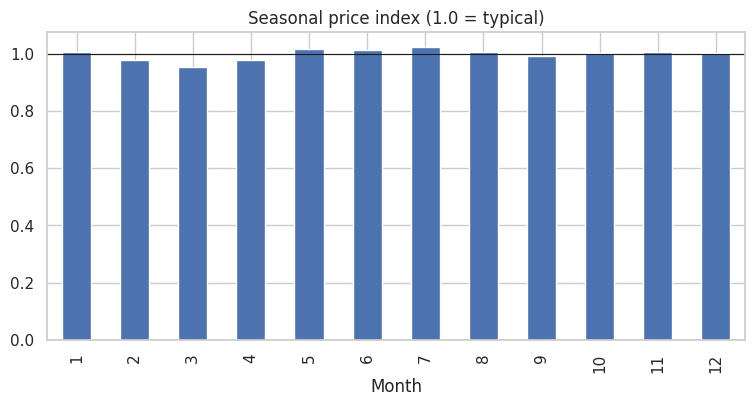

In [32]:
long = final[["Kitui", "Mandera", "Lodwar (Turkana)", "Marsabit"]].loc["2006-01":"2020-12"]
trend = long.rolling(12, center=True, min_periods=9).mean()
ratio = (long / trend)

idx = ratio.groupby(ratio.index.month).mean()
idx["average"] = idx.mean(axis=1)
display(idx.round(3))

idx["average"].plot(kind="bar", figsize=(9,4), title="Seasonal price index (1.0 = typical)")
plt.axhline(1, color="k", lw=0.8); plt.xlabel("Month"); plt.show()

In [33]:
trailing = final.rolling(12, min_periods=9).mean().shift(1)
gap = final / trailing - 1

for th in [0.15, 0.20, 0.25]:
    spikes = (gap > th)
    print(f"Threshold {th:.0%}: {int(spikes.sum().sum())} spike-months")

spikes = (gap > 0.20)
by_market = spikes.sum().sort_values(ascending=False)
by_month  = spikes.groupby(spikes.index.month).sum().sum(axis=1)
by_year   = spikes.groupby(spikes.index.year).sum().sum(axis=1)
display(by_market); display(by_month); display(by_year)

Threshold 15%: 189 spike-months
Threshold 20%: 139 spike-months
Threshold 25%: 102 spike-months


,0
market,
Kitui,40
Marsabit,27
Lodwar (Turkana),19
Mandera,19
Marigat (Baringo),10
Kajiado,9
Hola (Tana River),9
Kilifi,5
Garissa,1


,0
1,10
2,10
3,11
4,14
5,17
6,15
7,15
8,11
9,9
10,9


,0
2006,1
2007,3
2008,29
2009,12
2010,2
2011,34
2012,6
2013,2
2014,0
2015,1


In [34]:
def vol_for(d):
    return np.log(d.loc["2006-01":"2020-12"]).diff().std()

print(pd.DataFrame({"with_outlier": vol_for(final_keep[["Kitui","Mandera","Lodwar (Turkana)","Marsabit"]]),
                    "flagged_removed": vol_for(final[["Kitui","Mandera","Lodwar (Turkana)","Marsabit"]])}).round(3))

                  with_outlier  flagged_removed
market                                         
Kitui                    0.150            0.121
Mandera                  0.076            0.076
Lodwar (Turkana)         0.074            0.074
Marsabit                 0.075            0.075


In [35]:
spikes = (gap > 0.20)
valid = gap.notna()

rate_market = (spikes.sum() / valid.sum()).round(3).sort_values(ascending=False)
display(rate_market)

rate_year = (spikes.groupby(spikes.index.year).sum().sum(axis=1) /
             valid.groupby(valid.index.year).sum().sum(axis=1)).round(2)
display(rate_year)

,0
market,
Kitui,0.234
Marigat (Baringo),0.159
Marsabit,0.158
Kajiado,0.143
Hola (Tana River),0.143
Lodwar (Turkana),0.111
Mandera,0.111
Kilifi,0.079
Garissa,0.016


,0
2006,0.08
2007,0.06
2008,0.60
2009,0.25
2010,0.04
2011,0.71
2012,0.12
2013,0.04
2014,0.00
2015,0.02


In [36]:
future_max = gap[::-1].rolling(3, min_periods=3).max()[::-1].shift(-1)  # max gap over next 3 months
event = future_max > 0.20
ok = gap.notna() & future_max.notna()

warn = (gap > 0.10) & (gap <= 0.20)          # early-warning zone
calm = (gap <= 0.10)

hit  = event.where(warn & ok).stack().astype(float)
base = event.where(calm & ok).stack().astype(float)
print(f"After a warning: {hit.mean():.0%} turned into a spike (n={len(hit)})")
print(f"Otherwise:       {base.mean():.0%} (n={len(base)})")

After a warning: 27% turned into a spike (n=124)
Otherwise:       7% (n=709)


In [37]:
# Spike rate per market on the common 2015-2020 window
w = slice("2015-01", "2020-12")
spk, val = (gap.loc[w] > 0.20), gap.loc[w].notna()
print((spk.sum() / val.sum()).round(3).sort_values(ascending=False))

# Recall: of all spike onsets, how many had a warning in the 3 months before?
onset = (gap > 0.20) & (gap.shift(1) <= 0.20)
prior_warn = ((gap > 0.10) & (gap <= 0.20)).rolling(3).max().shift(1).fillna(0).astype(bool)
ok2 = onset.stack()
print(f"Spike onsets: {int(onset.sum().sum())}; "
      f"preceded by a warning: {int((onset & prior_warn).sum().sum())}")

market
Kitui                0.194
Marigat (Baringo)    0.159
Kajiado              0.143
Hola (Tana River)    0.143
Kilifi               0.079
Lodwar (Turkana)     0.028
Garissa              0.016
Mandera              0.000
Marsabit             0.000
dtype: float64
Spike onsets: 32; preceded by a warning: 22


In [38]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

mk = ["Kitui", "Mandera", "Lodwar (Turkana)", "Marsabit"]
rows = []
for m in mk:
    s = final[m].loc["2006-01":"2020-12"].dropna()
    s.index = s.index.to_timestamp()
    train, test = s.loc[:"2018-12"], s.loc["2019-01":]
    h = len(test)

    naive = pd.Series(train.iloc[-1], index=test.index)
    snaive = pd.Series(np.tile(train.iloc[-12:].values, 2)[:h], index=test.index)
    hw = ExponentialSmoothing(train, trend="add", damped_trend=True,
                              seasonal="add", seasonal_periods=12).fit()
    hwf = hw.forecast(h)

    rows.append({"market": m,
                 "naive": (test - naive).abs().mean(),
                 "seasonal_naive": (test - snaive).abs().mean(),
                 "holt_winters": (test - hwf).abs().mean()})

res = pd.DataFrame(rows).set_index("market").round(2)
res.loc["average"] = res.mean().round(2)
display(res)          # MAE in KES per KG

,naive,seasonal_naive,holt_winters
market,,,
Kitui,8.52,7.48,8.72
Mandera,10.99,13.45,10.73
Lodwar (Turkana),5.66,13.44,3.69
Marsabit,3.16,5.12,3.78
average,7.08,9.87,6.73


In [39]:
def warning_test(lo=0.10, th=0.20, h=3):
    fut = pd.DataFrame(np.maximum.reduce([gap.shift(-k).values for k in range(1, h+1)]),
                       index=gap.index, columns=gap.columns)
    ok = gap.notna() & fut.notna()
    warn = (gap > lo) & (gap <= th) & ok
    calm = (gap <= lo) & ok
    p_warn = ((fut > th) & warn).sum().sum() / warn.sum().sum()
    p_calm = ((fut > th) & calm).sum().sum() / calm.sum().sum()
    return round(p_warn, 2), round(p_calm, 2), int(warn.sum().sum())

for th in [0.15, 0.20, 0.25]:
    for h in [2, 3]:
        print(f"spike>{th:.0%}, horizon {h}m ->", warning_test(th/2, th, h))   # (after warning, baseline, n)

spike>15%, horizon 2m -> (np.float64(0.21), np.float64(0.07), 122)
spike>15%, horizon 3m -> (np.float64(0.27), np.float64(0.1), 121)
spike>20%, horizon 2m -> (np.float64(0.24), np.float64(0.04), 124)
spike>20%, horizon 3m -> (np.float64(0.27), np.float64(0.07), 124)
spike>25%, horizon 2m -> (np.float64(0.18), np.float64(0.03), 117)
spike>25%, horizon 3m -> (np.float64(0.21), np.float64(0.05), 117)
